In [ ]:
import struct

##Sensor Values to send
a = 533.510121
init_a = a
a = a/1000
a = a*255 #Scaling allows higher accuracy
# a = a/10
# a = a*255
b = 533.510121
init_b = b

# Pack the value into 4 bytes
packed_value_1 = struct.pack('B', int(a))
packed_value_2 = struct.pack('f', b)
packed_size = len(packed_value_1)

# Now packed_value is a bytes object containing the 4-byte representation of the value
print(f"{packed_value_1},size: {packed_size}bytes")
packet = packed_value_1 + packed_value_2

packet_size = len(packet)
print(f"{packet},size: {packet_size}bytes")

unpacked_value_1 = packet[:1]
unpacked_value_2 = packet[1:5]

unpacked_value_1 = struct.unpack('B',unpacked_value_1)
unpacked_value_2 = struct.unpack('f',unpacked_value_2)

print("\n1 BYTES:")
print(f"Before: {init_a}\n After: {unpacked_value_1[0]*1000/255}")
diff_a = abs(init_a - unpacked_value_1[0]*1000/255)
print(f"Difference: {diff_a}\n")

print("4 BYTES:")
print(f"Before: {init_b}\n After: {unpacked_value_2[0]}")
diff_b = abs(init_b - unpacked_value_2[0])
print(f"Difference: {diff_b}")


b'\x88',size: 1bytes
b'\x88\xa6`\x05D',size: 5bytes

1 BYTES:
Before: 533.510121
 After: 533.3333333333334
Difference: 0.17678766666665524

4 BYTES:
Before: 533.510121
 After: 533.5101318359375
Difference: 1.0835937473530066e-05


In [ ]:
from datetime import datetime
import math

In [ ]:
timestamp = int(datetime.today().strftime('%Y%m%d%H%M%S'))



In [ ]:
# Image dimensions and color depth
width = 640   # pixels
height = 512  # pixels
color_depth = 16  # bits per pixel


# Total size of the image in bits
total_bits = width * height * color_depth

# Convert the total size to bytes and kilobytes
total_bytes = total_bits / 8
total_kilobytes = total_bytes / 1024

total_bits, total_bytes, total_kilobytes


(5242880, 655360.0, 640.0)

In [ ]:
# Packet structure sizes
send_byte_size = 1  # byte
message_id_size = 1  # byte
timestamp_size = 4  # bytes
crc_size = 1        # byte
end_byte_size = 1   # byte
image_data_size = 31
# Total overhead size per packet
packet_overhead = send_byte_size + message_id_size + timestamp_size + crc_size + end_byte_size

# Size available for image data per packet
image_data_per_packet = image_data_size - packet_overhead  # bytes

# Total number of packets needed
total_packets_with_format = total_bytes / image_data_per_packet

# Rounding up to the nearest whole packet
total_packets_with_format = math.ceil(total_packets_with_format)

total_packets_with_format


28494

In [ ]:
def crc8(data):
    """
    Calculates the CRC-8 checksum for the given data.

    :param data: The data for which to calculate the CRC-8.
    :return: The CRC-8 checksum.
    """
    crc = 0
    for byte in data:
        crc ^= byte
        for _ in range(8):
            if crc & 0x80:
                crc = (crc << 1) ^ 0x07
            else:
                crc <<= 1
            crc &= 0xFF  # Ensure CRC remains within 8 bits
    return crc



In [ ]:
import struct
import time

import matplotlib.pyplot as plt
import numpy as np

# Generate a simulated IR image with random data
# Each pixel is represented by a 16-bit integer
ir_image = np.random.randint(0, 2**color_depth, (height, width), dtype=np.uint16)

# Convert the image to a byte array for packetization
# Each pixel is represented by 2 bytes (16 bits)
ir_image_bytes = ir_image.tobytes()

# Checking the size of the generated byte array to confirm it matches our earlier calculation
len(ir_image_bytes) == total_bytes  # This should be True if the size matches

def create_packets(image_data, payload_size):
    """
    Splits the image data into packets with the specified format.

    :param image_data: The byte array of the image.
    :param payload_size: The size of the image data in each packet.
    :return: A list of packets.
    """
    packets = []
    message_id = 0  # Initialize message ID
    send_byte = 0x01  # Example Send Byte
    end_byte = 0x04  # Example End Byte

    for i in range(0, len(image_data), payload_size):
        # Extract the part of the image for this packet
        packet_data = image_data[i:i + payload_size]
        # Compute CRC for the serialized line
        crc = crc8(packet_data)

        # Create a simple timestamp (just for demonstration purposes)
        timestamp = int(time.time())

        # Packet structure: [Send Byte, Message ID, Timestamp, Image Data, CRC, End Byte]
        packet = struct.pack(f'!BBIB{len(packet_data)}sBB',
                             send_byte, message_id, timestamp, len(packet_data), packet_data, crc, end_byte)


        packets.append(packet)

        # Increment the message ID for the next packet
        message_id = (message_id) % 256  # Keep it within 1 byte

    return packets

# Packetize the image data
packets = create_packets(ir_image_bytes, image_data_per_packet)  # 24 bytes for image data
print(len(packets[0]))
# Check the number of packets
len(packets) == total_packets_with_format  # This should be True if the number of packets matches


32


True

In [ ]:
def check_packet_crc(packet):
    """
    Checks the CRC of a given packet.

    :param packet: The packet to check.
    :return: True if the CRC is correct, False otherwise.
    """
    # Extract the header and the CRC from the packet
    header_format = '!BBIB'
    header_size = struct.calcsize(header_format)
    send_byte, message_id, timestamp, data_length = struct.unpack(header_format, packet[:header_size])

    # Extract the image data and the packet's CRC
    data_start_index = header_size
    data_end_index = data_start_index + data_length
    data = packet[data_start_index:data_end_index]
    packet_crc = packet[data_end_index]

    # Calculate the CRC for the data
    calculated_crc = crc8(data)

    return calculated_crc == packet_crc

In [ ]:
check_packet_crc(packets[0])

True

In [ ]:
import datetime

def translate_packet_info(packet):
    """
    Translates the timestamp and message ID from the given packet.

    :param packet: The packet from which to extract the timestamp and message ID.
    :return: A dictionary containing the translated timestamp and message ID.
    """
    # Extract the timestamp and message ID
    header_format = '!BBIB'
    send_byte, message_id, timestamp, data_length = struct.unpack(header_format, packet[:struct.calcsize(header_format)])

    # Convert the timestamp to a readable format (assuming it's a Unix timestamp)
    readable_timestamp = datetime.datetime.utcfromtimestamp(timestamp).strftime('%Y-%m-%d %H:%M:%S')

    return {"Message ID": message_id, "Timestamp": readable_timestamp}

# Extract and translate the timestamp and message ID from the dummy packet
packet_info = translate_packet_info(packets[0])
packet_info

{'Message ID': 0, 'Timestamp': '2024-01-11 21:56:18'}

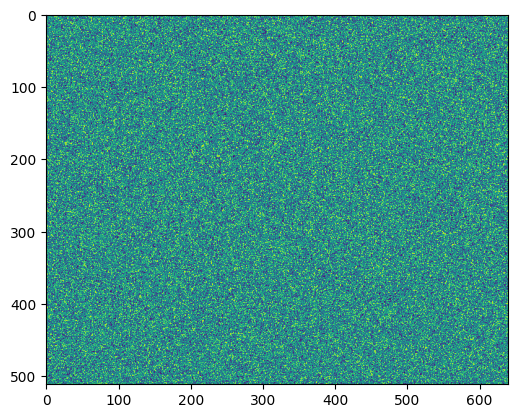

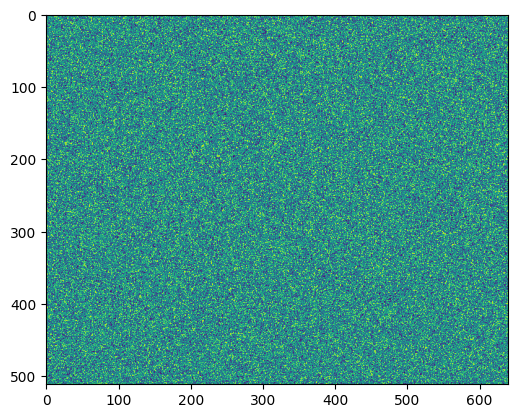

In [ ]:
def reassemble_image_correctly_v2(packets):
    """
    Reassembles the image from the given packets, correctly handling the packet structure.
    Assumes the structure [Send Byte, Message ID, Timestamp, Image Data Length, Image Data, CRC, End Byte].

    :param packets: The list of packets.
    :return: The reassembled byte array of the image.
    """
    reassembled_data = bytearray()

    for packet in packets:
        # Extract the header to determine the length of the image data
        # The format is: Send Byte (1 byte), Message ID (1 byte), Timestamp (4 bytes), Data Length (1 byte)
        header_format = '!BBIB'
        header_size = struct.calcsize(header_format)
        send_byte, message_id, timestamp, data_length = struct.unpack(header_format, packet[:header_size])

        # Extract the image data based on the determined length
        data_start_index = header_size  # Start index of the image data
        data_end_index = data_start_index + data_length  # End index of the image data
        data = packet[data_start_index:data_end_index]

        # Append the image data to the reassembled data
        reassembled_data.extend(data)

    return reassembled_data

# Reassemble the image from the packets with the corrected function
reassembled_image_bytes_correct_v2 = reassemble_image_correctly_v2(packets)

# Convert the reassembled byte array back to a 2D array
reassembled_image_correct_v2 = np.frombuffer(reassembled_image_bytes_correct_v2, dtype=np.uint16).reshape(height, width)

# Check if the reassembled image matches the original image
np.array_equal(ir_image, reassembled_image_correct_v2)  # This should be True if the images match


plt.imshow(ir_image)
plt.figure()
plt.imshow(reassembled_image_correct_v2)

209


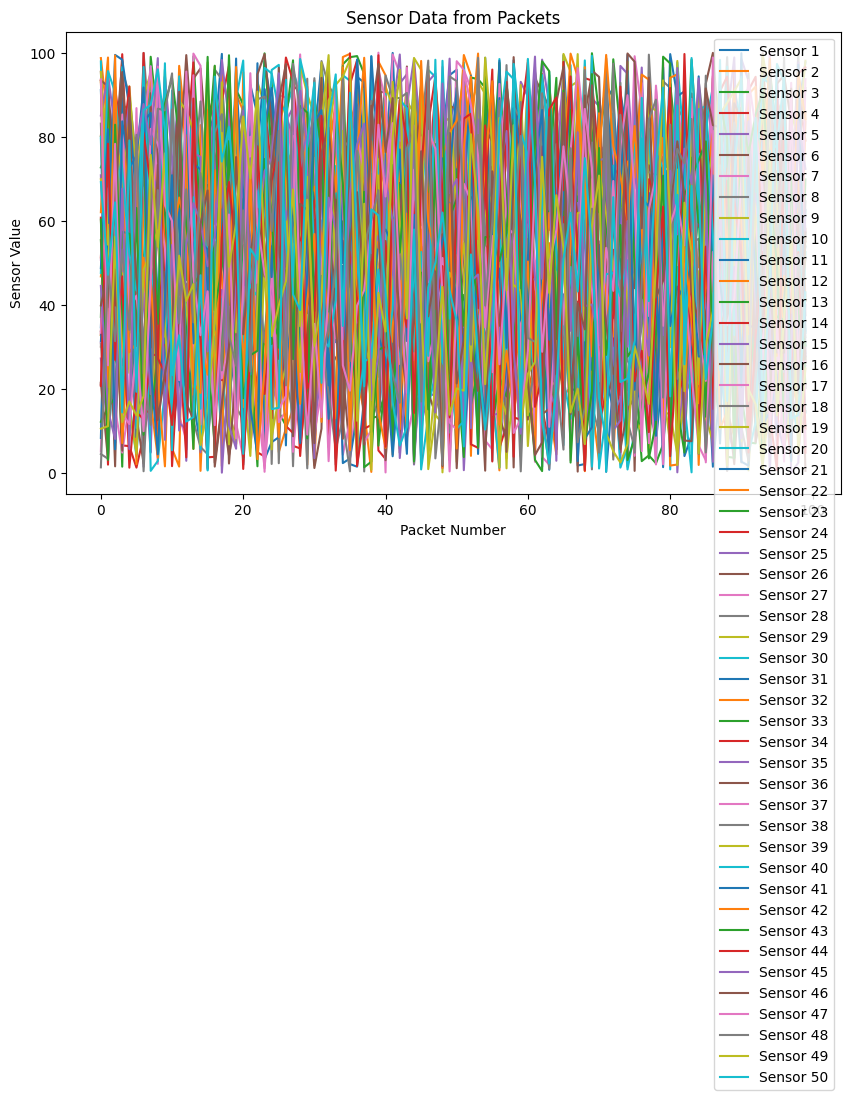

[(-2.988215825894258e-07, 24.91193550745283, 24.911935806274414),
 (1.2898018653118015e-08, 2.637432826542428, 2.637432813644409),
 (-2.1304054698134678e-07, 17.809776093111797, 17.809776306152344),
 (-2.616875978134203e-07, 14.032580113983789, 14.032580375671387),
 (-3.344324284171307e-08, 6.5118698739359075, 6.51186990737915),
 (3.4173263663284104e-09, 0.12216216667492524, 0.12216216325759888),
 (-3.0078999202487466e-07, 21.304364857291063, 21.304365158081055),
 (-9.071685624917336e-09, 7.259232035148285, 7.259232044219971),
 (-3.389762426309062e-07, 25.011275906140945, 25.011276245117188),
 (-4.16097638122892e-07, 13.394035876932147, 13.394036293029785),
 (-1.6477110520440874e-07, 15.95929606173036, 15.959296226501465),
 (1.2383752157063554e-07, 14.809529428341916, 14.809529304504395),
 (-1.3698098566550243e-07, 7.0554789127016315, 7.055479049682617),
 (3.037460127863767e-08, 1.2318399256230144, 1.231839895248413),
 (2.422626899090119e-08, 10.19834806957539, 10.198348045349121),
 (-

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np
import random

# Number of sensors
num_sensors = 50

# Generate 100 packets with random sensor data
num_packets = 100
sensor_data_packets = []

for _ in range(num_packets):
    # Generate random sensor data (6 floating-point numbers)
    sensor_values = [((random.uniform(0, 100)/1000)*255) for _ in range(num_sensors)]
    sensor_values_old = sensor_values
    sensor_data_bytes = struct.pack(f'!{num_sensors}f', *sensor_values)

    # Dummy packet components (for simplicity)
    send_byte = 0x01
    message_id = random.randint(0, 255)
    timestamp = int(time.time())
    data_length = len(sensor_data_bytes)
    crc = crc8(sensor_data_bytes)
    end_byte = 0x04

    # Create the packet
    packet = struct.pack(f'!BBIB{data_length}sBB', send_byte, message_id, timestamp, data_length, sensor_data_bytes, crc, end_byte)

    sensor_data_packets.append(packet)

# Initialize lists to store sensor data
sensor_data = [[] for _ in range(num_sensors)]


import matplotlib.pyplot as plt

# Reinitialize lists to store sensor data
sensor_data = [[] for _ in range(num_sensors)]

# Extract sensor data from each packet and store it
for packet in sensor_data_packets:
    header_format = '!BBIB'
    header_size = struct.calcsize(header_format)
    send_byte, message_id, timestamp, data_length = struct.unpack(header_format, packet[:header_size])
    data_start_index = header_size
    data_end_index = data_start_index + data_length
    sensor_values = struct.unpack(f'!{num_sensors}f', packet[data_start_index:data_end_index])
    #sensor_values = (sensor_values / 255) * 1000

    for i in range(num_sensors):
        sensor_data[i].append((sensor_values[i]/255)*1000)

# Plot the sensor data
plt.figure(figsize=(10, 6))
for i in range(num_sensors):
    plt.plot(sensor_data[i], label=f'Sensor {i+1}')

print(len(packet))
plt.xlabel('Packet Number')
plt.ylabel('Sensor Value')
plt.title('Sensor Data from Packets')
plt.legend()
plt.show()


# Compare the rescaled values with the original floating-point values
comparisons_uint8 = zip(sensor_values_old, sensor_values)
differences_uint8 = [(original - rescaled, original, rescaled) for original, rescaled in comparisons_uint8]

differences_uint8